# Crop Recommendation Dataset — Clustering Analysis

##  Problem Statement

Agricultural conditions such as soil nutrients, temperature, humidity, rainfall, and other environmental factors influence crop suitability. Understanding similarities among agricultural observations can help reveal patterns in soil and environmental conditions.

The objective of this project is to apply unsupervised machine learning techniques to the Crop Recommendation dataset to identify groups of observations with similar agricultural characteristics.

The project implements K-Means and Agglomerative Hierarchical Clustering, compares their performance using clustering evaluation metrics, and visualizes the resulting clusters using PCA and t-SNE.

The known crop labels are excluded during model training and used only after clustering to interpret the composition of the discovered groups.

##  Dataset Description and Source

**Dataset Name:** Crop Recommendation Dataset

**Dataset File:** `Crop_recommendationV2.csv`

**Dataset Source:** [Crop Recommendation Dataset on Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset)

**Dataset Overview:**
- Total observations: 2,200
- Total columns: 23
- Known crop categories: 22
- Missing values: 0
- Duplicate records: 0

The dataset contains agricultural measurements related to soil nutrients, environmental conditions, and other agricultural characteristics. These features are used to investigate similarities among observations through clustering.

The `label` column represents the known crop category. It is excluded from clustering model inputs and retained for post-clustering interpretation.

**Note:** The source link above identifies the commonly used Crop Recommendation dataset. The team should verify whether the uploaded `Crop_recommendationV2.csv` is the same version or a modified/extended version before describing its provenance.

##  Project Objectives

1. Explore the agricultural dataset and understand its feature distributions.
2. Select suitable features and standardize numerical measurements for distance-based clustering.
3. Implement K-Means and Agglomerative Hierarchical Clustering.
4. Use the Elbow Method to investigate an appropriate number of K-Means clusters.
5. Compare hierarchical linkage strategies using a dendrogram and clustering metrics.
6. Evaluate cluster quality using Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index.
7. Visualize cluster assignments using PCA and t-SNE.
8. Interpret the discovered clusters using the known crop labels after model fitting.

## 1. Dataset Loading and Initial Inspection

### Objective
The objective of this section is to load the crop recommendation dataset and examine its structure, feature types, missing values, duplicate records, and crop categories before performing clustering.

In [1]:

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Load the dataset
df = pd.read_csv("Crop_recommendationV2.csv")

# Step 3: Display the dataset dimensions
print("Dataset Shape:", df.shape)

# Step 4: Display the first five records
display(df.head())

# Step 5: Inspect column names and data types
print("\nDataset Information:")
df.info()

# Step 6: Check missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# Step 7: Check duplicate records
print("\nNumber of Duplicate Records:", df.duplicated().sum())

# Step 8: Check crop categories
print("\nNumber of Crop Categories:", df["label"].nunique())

# Step 9: Check the distribution of crop labels
print("\nCrop Category Counts:")
print(df["label"].value_counts().sort_index())


Dataset Shape: (2200, 23)


,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,29.446064,2,...,3.121395,4,11.743910,57.607308,188.194958,1,2.719614,3,95.649985,1.193293
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,12.851183,3,...,2.142021,4,16.797101,74.736879,70.963629,1,4.714427,2,77.265694,1.752672
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,29.363913,2,...,1.474974,1,12.654395,1.034478,191.976077,1,30.431736,2,18.192168,3.035541
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,26.207732,3,...,8.393907,1,10.864360,24.091888,55.761388,3,10.861071,3,82.818720,1.273341
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,28.236236,2,...,5.202285,3,13.852910,38.811481,185.259702,2,47.190777,3,25.466499,2.578671



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       2200 non-null   int64  
 1   P                       2200 non-null   int64  
 2   K                       2200 non-null   int64  
 3   temperature             2200 non-null   float64
 4   humidity                2200 non-null   float64
 5   ph                      2200 non-null   float64
 6   rainfall                2200 non-null   float64
 7   label                   2200 non-null   str    
 8   soil_moisture           2200 non-null   float64
 9   soil_type               2200 non-null   int64  
 10  sunlight_exposure       2200 non-null   float64
 11  wind_speed              2200 non-null   float64
 12  co2_concentration       2200 non-null   float64
 13  organic_matter          2200 non-null   float64
 14  irrigation_frequency    2200 

## 2. Exploratory Data Analysis (EDA)

### 2.1 Dataset Summary

**Objective:** Examine the numerical features using descriptive statistics to understand their ranges, central values, and variability.

This step helps identify differences in measurement scales and possible unusual observations before preprocessing the dataset for clustering.

In [2]:

# Step 2.1: Display descriptive statistics
display(df.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56
soil_moisture,2200.0,20.15,5.79,10.02,15.18,20.09,25.26,30.00
soil_type,2200.0,1.99,0.81,1.00,1.00,2.00,3.00,3.00
sunlight_exposure,2200.0,8.57,2.00,5.00,6.90,8.61,10.22,11.99


### 2.2 Feature Type Identification

**Objective:** Separate continuous numerical measurements from integer-coded categorical features. This helps us choose appropriate visualizations and avoid assuming that category codes represent meaningful numerical distances.

In [3]:

# Step 2.2: Define feature groups
continuous_features = [
    "N", "P", "K", "temperature", "humidity", "ph", "rainfall",
    "soil_moisture", "sunlight_exposure", "wind_speed",
    "co2_concentration", "organic_matter", "crop_density",
    "pest_pressure", "fertilizer_usage", "urban_area_proximity",
    "frost_risk", "water_usage_efficiency"
]

coded_features = [
    "soil_type", "irrigation_frequency",
    "growth_stage", "water_source_type"
]

print("Continuous features:", len(continuous_features))
print("Coded features:", len(coded_features))
print("\nCoded Feature Values:")

for col in coded_features:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


Continuous features: 18
Coded features: 4

Coded Feature Values:

soil_type
soil_type
1    735
2    749
3    716
Name: count, dtype: int64

irrigation_frequency
irrigation_frequency
1    366
2    348
3    361
4    398
5    366
6    361
Name: count, dtype: int64

growth_stage
growth_stage
1    738
2    725
3    737
Name: count, dtype: int64

water_source_type
water_source_type
1    721
2    750
3    729
Name: count, dtype: int64


### 2.3 Distribution Analysis

**Objective:** Visualize the distribution of each continuous feature using histograms. These plots help reveal concentration, skewness, and variation in the agricultural measurements.

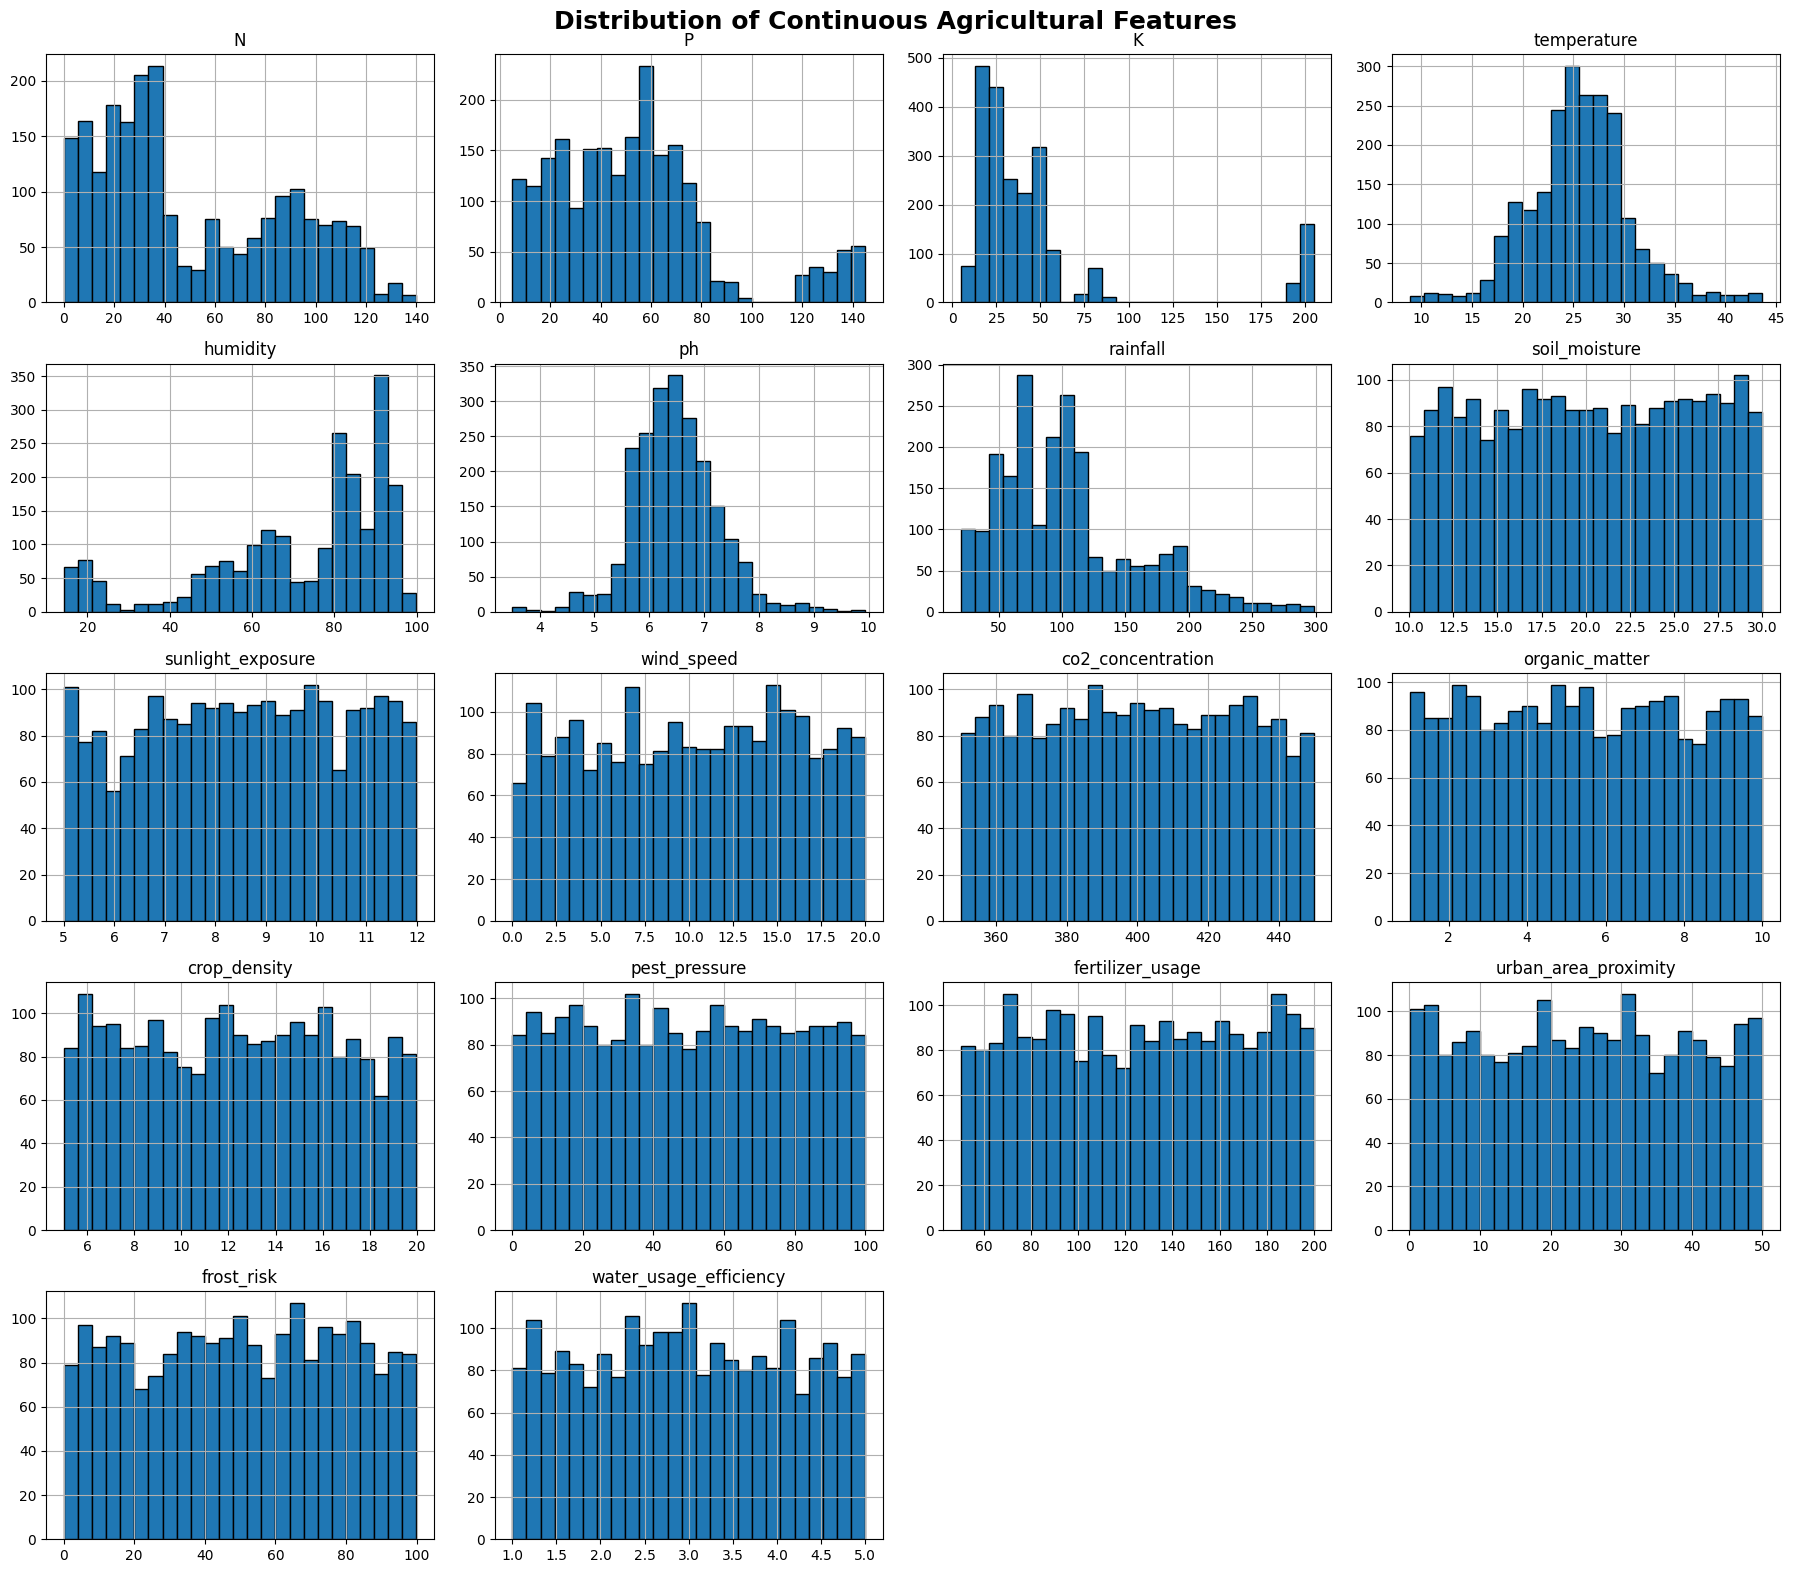

In [4]:

# Step 2.3: Plot distributions of continuous features
df[continuous_features].hist(
    figsize=(18, 16),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Continuous Agricultural Features",
    fontsize=18,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


### 2.4 Outlier Inspection

**Objective:** Use boxplots to identify potential outliers in the continuous features. Unusual observations will be investigated before deciding whether any treatment is appropriate.

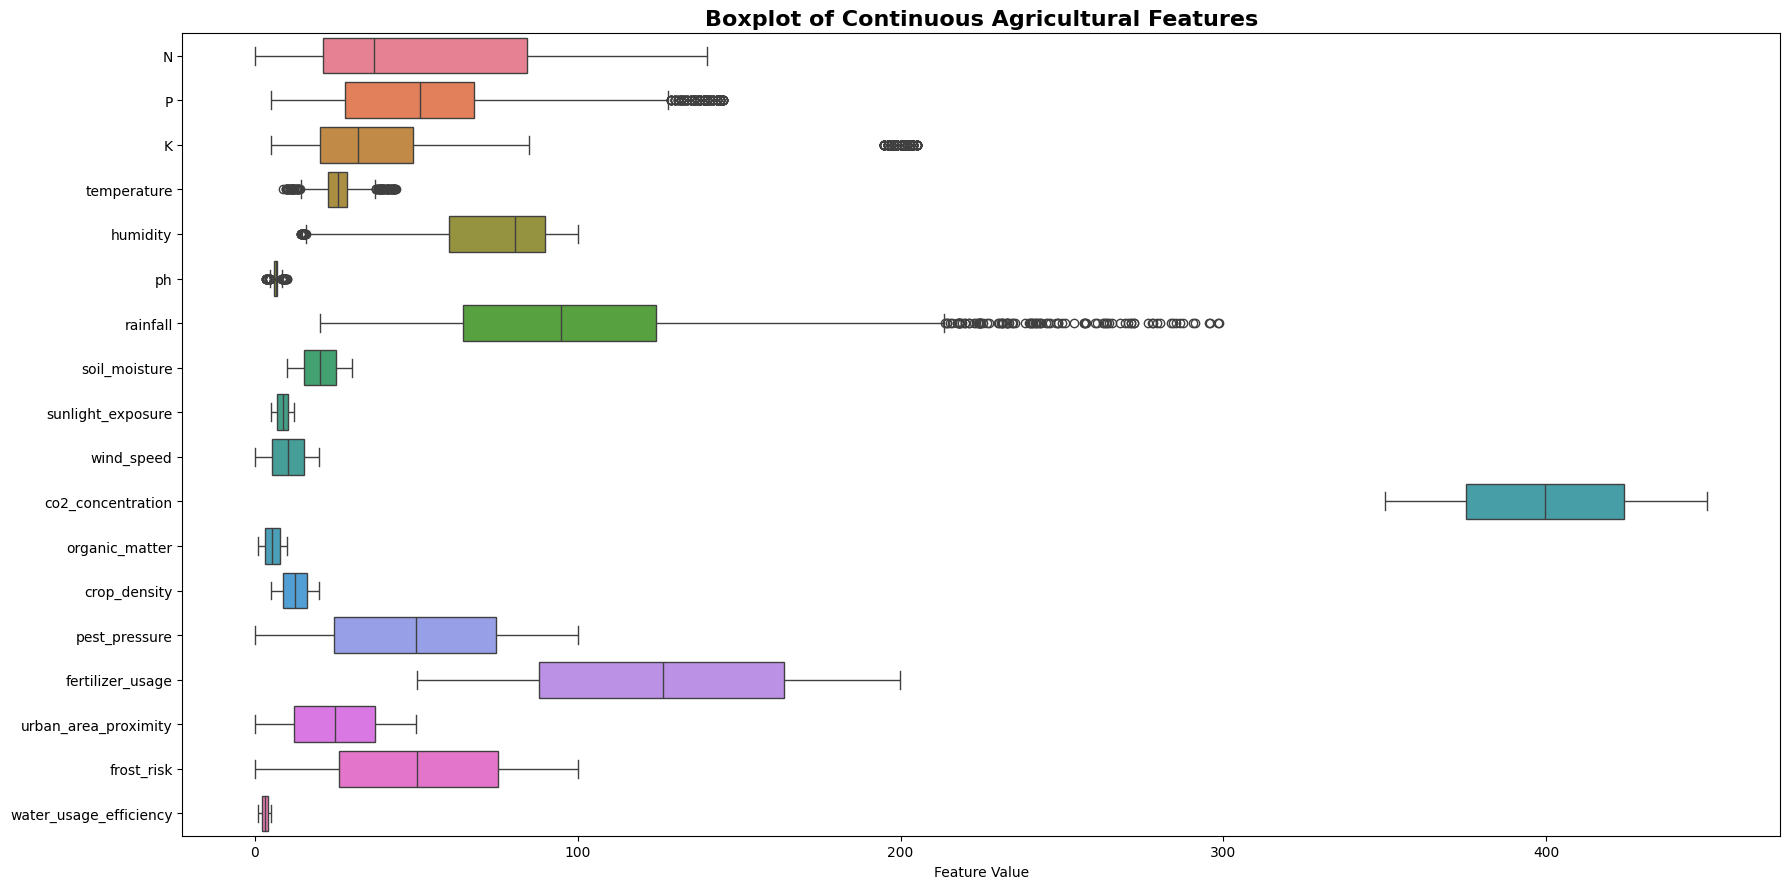

In [5]:

# Step 2.4: Visualize potential outliers
plt.figure(figsize=(18, 9))

sns.boxplot(
    data=df[continuous_features],
    orient="h"
)

plt.title(
    "Boxplot of Continuous Agricultural Features",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()


### 2.5 Correlation Analysis

**Objective:** Examine linear relationships among continuous features using a correlation matrix and heatmap. This helps identify strongly related variables and possible redundancy before clustering.

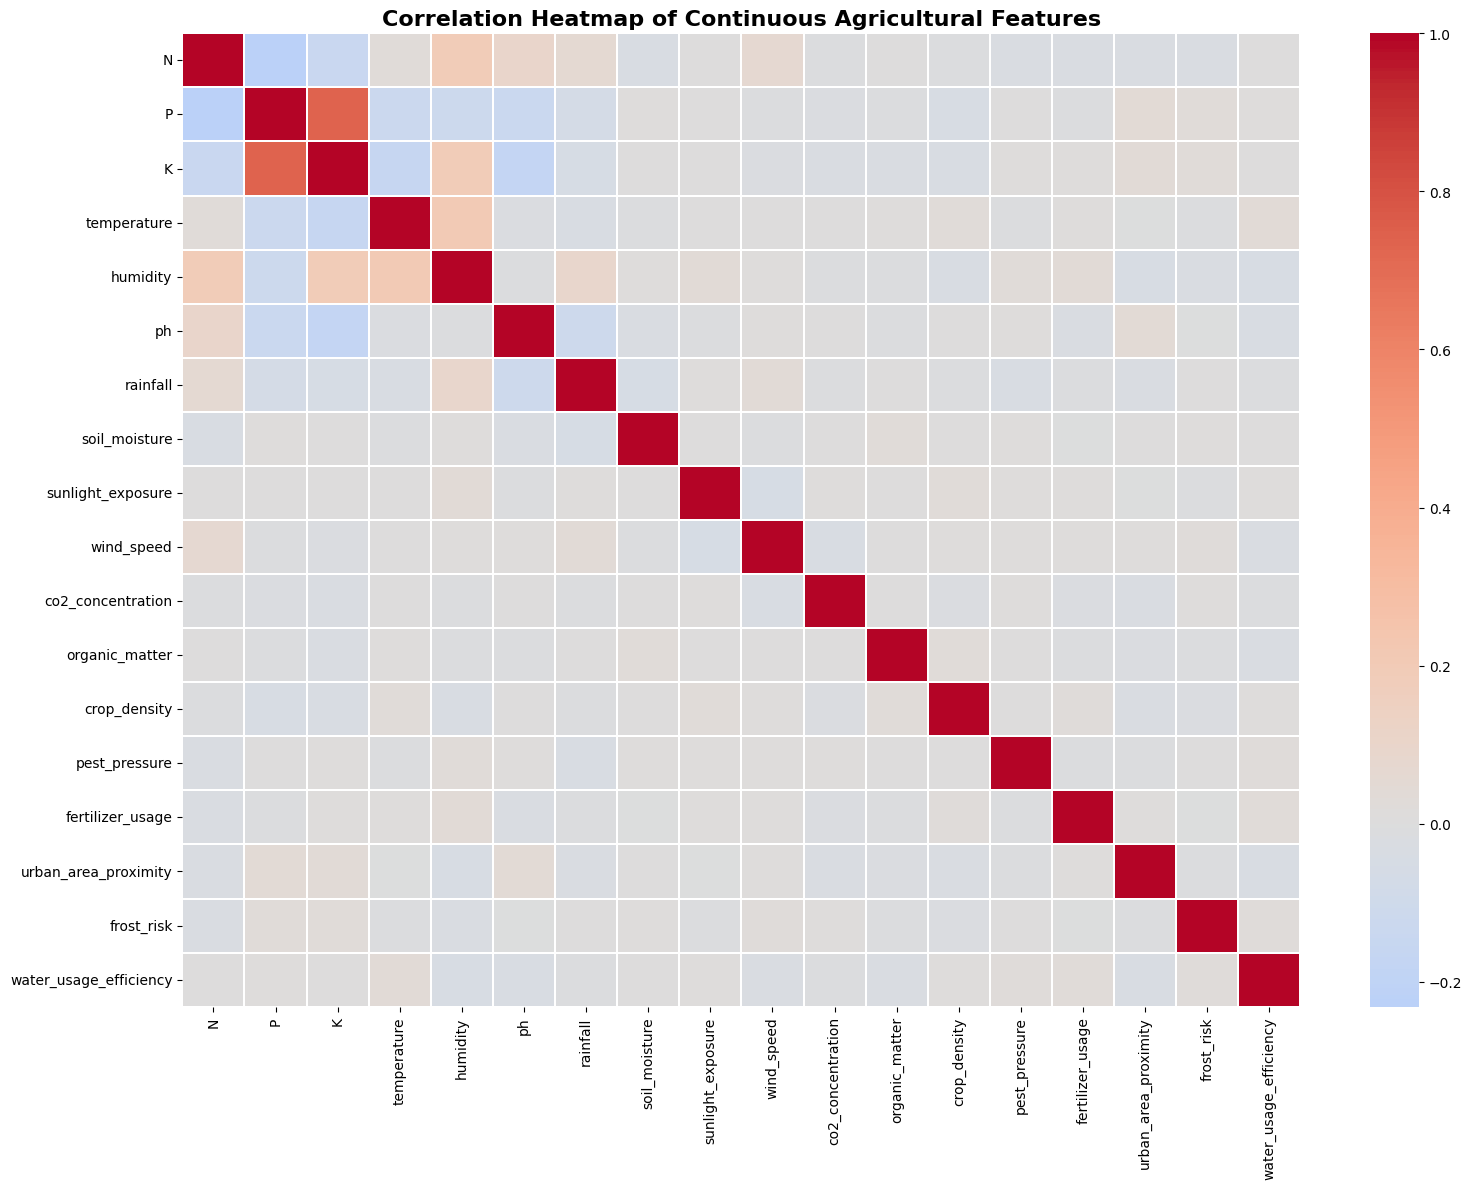

In [6]:

# Step 2.5: Calculate and visualize correlations
correlation_matrix = df[continuous_features].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title(
    "Correlation Heatmap of Continuous Agricultural Features",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()



### 2.6 Final Interpretation of Exploratory Data Analysis

The exploratory data analysis examined the distributions, variability, potential outliers, and relationships among the continuous agricultural features in the Crop Recommendation dataset.

The descriptive statistics showed that the features have different numerical ranges and levels of variability. For example, nitrogen (N) ranges from 0 to 140, rainfall ranges from approximately 20.21 to 298.56, and temperature ranges from approximately 8.83 to 43.68. These differences make feature standardization important before applying distance-based clustering algorithms.

The histograms were used to inspect the distributions of the continuous features and identify possible skewness or concentration in particular value ranges. The boxplots were used to identify potential outliers. Such observations should not automatically be removed because they may represent meaningful agricultural conditions.

The correlation heatmap was generated to examine linear relationships between continuous features. Correlated features may contribute overlapping information to distance calculations, so these relationships should be considered when interpreting the clustering results.

The dataset contains 2,200 observations, 22 known crop categories, no missing values, and no duplicate records. These characteristics provide a consistent starting point for clustering analysis.

Overall, the EDA supports the need for feature standardization and careful interpretation of cluster quality. Potential outliers and relationships between features should be considered when evaluating the resulting groups. No observations were removed solely because they appeared unusual in the exploratory visualizations.


## 3. Data Preprocessing



### 3.1 Feature Selection for Clustering

Clustering was performed using the 18 continuous numerical features in the Crop Recommendation dataset.

The following four coded categorical features were excluded from the primary clustering analysis:

- `soil_type`
- `irrigation_frequency`
- `growth_stage`
- `water_source_type`

These variables use numerical codes to represent categories. Treating such codes directly as continuous numerical values can introduce artificial distances between categories. For example, a category coded as 3 is not necessarily more similar to a category coded as 2 than to one coded as 1.

Therefore, the primary clustering analysis focuses on continuous agricultural measurements, such as soil nutrients, temperature, humidity, pH, and rainfall. These features can be standardized and used with distance-based algorithms such as K-Means and Agglomerative Hierarchical Clustering.

All selected continuous features were standardized before clustering so that features with larger numerical ranges would not dominate the distance calculations.

This feature-selection decision has a limitation: categorical variables may contain useful agricultural information. Future experiments could encode these variables appropriately and compare the resulting clusters with those obtained using continuous features alone.


In [7]:

# Step 3.1: Select continuous agricultural features
continuous_features = [
    "N", "P", "K", "temperature", "humidity", "ph", "rainfall",
    "soil_moisture", "sunlight_exposure", "wind_speed",
    "co2_concentration", "organic_matter", "crop_density",
    "pest_pressure", "fertilizer_usage", "urban_area_proximity",
    "frost_risk", "water_usage_efficiency"
]

# Keep known crop labels separate for later interpretation
y_true = df["label"].copy()

# Create the feature dataset without the label column
X = df[continuous_features].copy()

print("Number of selected features:", len(continuous_features))
print("Feature matrix shape:", X.shape)
print("\nSelected Features:")
print(X.columns.tolist())

print("\nMissing values in selected features:", X.isnull().sum().sum())
print("Duplicate rows in selected features:", X.duplicated().sum())
print("Crop labels kept separately:", y_true.shape)


Number of selected features: 18
Feature matrix shape: (2200, 18)

Selected Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'urban_area_proximity', 'frost_risk', 'water_usage_efficiency']

Missing values in selected features: 0
Duplicate rows in selected features: 0
Crop labels kept separately: (2200,)


### 3.2 Standardization of Features

K-Means and distance-based hierarchical clustering can be affected by differences in feature scales. Standardization transforms each feature to have approximately zero mean and unit standard deviation.

The original dataset will remain unchanged. We will create a separate standardized matrix for clustering.

In [8]:

# Step 3.2: Standardize the selected features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert the scaled array into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=continuous_features,
    index=X.index
)

print("Scaled feature matrix shape:", X_scaled_df.shape)

print("\nFeature means after scaling:")
print(X_scaled_df.mean().round(3))

print("\nFeature standard deviations after scaling:")
print(X_scaled_df.std(ddof=0).round(3))

display(X_scaled_df.head())


Scaled feature matrix shape: (2200, 18)

Feature means after scaling:
N                        -0.0
P                         0.0
K                        -0.0
temperature               0.0
humidity                 -0.0
ph                       -0.0
rainfall                  0.0
soil_moisture             0.0
sunlight_exposure         0.0
wind_speed               -0.0
co2_concentration        -0.0
organic_matter           -0.0
crop_density              0.0
pest_pressure            -0.0
fertilizer_usage         -0.0
urban_area_proximity     -0.0
frost_risk               -0.0
water_usage_efficiency    0.0
dtype: float64

Feature standard deviations after scaling:
N                         1.0
P                         1.0
K                         1.0
temperature               1.0
humidity                  1.0
ph                        1.0
rainfall                  1.0
soil_moisture             1.0
sunlight_exposure         1.0
wind_speed                1.0
co2_concentration         1.0
o

,N,P,K,temperature,humidity,ph,rainfall,soil_moisture,sunlight_exposure,wind_speed,co2_concentration,organic_matter,crop_density,pest_pressure,fertilizer_usage,urban_area_proximity,frost_risk,water_usage_efficiency
0,1.068797,-0.344551,-0.101688,-0.935587,0.472666,0.043302,1.810361,1.604632,0.053402,-0.010642,1.264517,-0.900010,-0.139892,0.268583,1.431502,-1.520687,1.586950,-1.577155
1,0.933329,0.140616,-0.141185,-0.759646,0.397051,0.734873,2.242058,-1.260307,-1.408916,0.327152,0.063442,-1.276012,1.036221,0.861716,-1.260091,-1.383309,0.943555,-1.086204
2,0.255986,0.049647,-0.081939,-0.515898,0.486954,1.771510,2.921066,1.590450,0.652660,-0.195128,-1.484829,-1.532106,0.072020,-1.690325,1.518316,0.387773,-1.123843,0.039735
3,0.635298,-0.556811,-0.160933,0.172807,0.389805,0.660308,2.537048,1.045567,-0.273609,-0.384705,-1.264147,1.124219,-0.344604,-0.891932,-1.609129,-0.960007,1.137894,-1.506899
4,0.743673,-0.344551,-0.121436,-1.083647,0.454792,1.497868,2.898373,1.395768,-0.225170,1.584806,0.376536,-0.101112,0.350971,-0.382247,1.364110,1.541923,-0.869263,-0.361247


### 3.3 Verification of Standardization

This section compares the original feature scales with the standardized values to verify that the preprocessing step has worked correctly.

In [9]:

# Step 3.3: Compare original and standardized feature statistics
scaling_comparison = pd.DataFrame({
    "Original Mean": X.mean(),
    "Original Std": X.std(ddof=0),
    "Scaled Mean": X_scaled_df.mean(),
    "Scaled Std": X_scaled_df.std(ddof=0)
})

display(scaling_comparison.round(3))


,Original Mean,Original Std,Scaled Mean,Scaled Std
N,50.552,36.909,-0.0,1.0
P,53.363,32.978,0.0,1.0
K,48.149,50.636,-0.0,1.0
temperature,25.616,5.063,0.0,1.0
humidity,71.482,22.259,-0.0,1.0
ph,6.469,0.774,-0.0,1.0
rainfall,103.464,54.946,0.0,1.0
soil_moisture,20.151,5.792,0.0,1.0
sunlight_exposure,8.571,1.999,0.0,1.0
wind_speed,10.171,5.738,-0.0,1.0


### 3.4 Final Interpretation of Data Preprocessing

The feature selection step separated the continuous agricultural measurements from the known crop labels. The label column was excluded from clustering model inputs to avoid using the known crop categories to form the clusters.

The selected features were standardized using `StandardScaler`. The resulting feature matrix contains 2,200 observations and 18 features. Standardization places the selected measurements on comparable scales, helping prevent variables with larger numerical magnitudes from dominating distance-based clustering.

The four integer-coded features were excluded temporarily because their category definitions need to be verified before deciding how to encode them. The standardized feature matrix is now ready for the initial clustering experiments using K-Means and Agglomerative Clustering.

## 4. K-Means Clustering

### 4.1 Introduction

K-Means is an unsupervised machine learning algorithm that divides observations into a specified number of clusters. It assigns each observation to the nearest cluster centroid and updates the centroids to reduce the within-cluster sum of squared distances.

In this project, K-Means will be applied to standardized agricultural features to identify groups of observations with similar agricultural conditions.

The known crop label will not be used to train the model.

### 4.2 Elbow Method

**Objective:** Evaluate different numbers of clusters using inertia and plot an Elbow curve to identify a reasonable candidate value for \(k\).

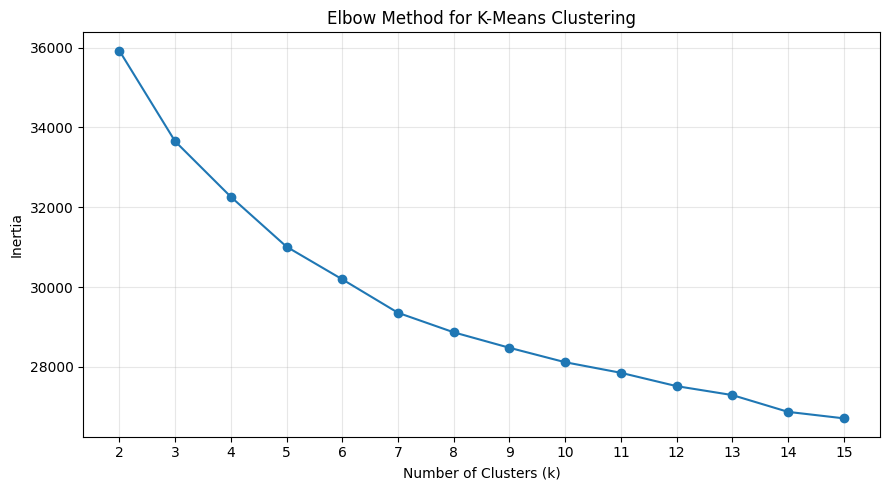

In [10]:

# Step 4.2: Calculate inertia for different cluster counts
from sklearn.cluster import KMeans

inertia_values = []
k_values = range(2, 16)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled_df)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 4.3 K-Means Model Training

**Objective:** Fit a K-Means model using a provisional value of five clusters and assign a cluster ID to each observation. The cluster count will be evaluated further before final model selection.

In [11]:

# Step 4.3: Train the initial K-Means model
kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled_df)

# Store cluster assignments separately from the input features
df["KMeans_Cluster"] = kmeans_labels

print("K-Means model trained successfully.")
print("\nCluster sizes:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nCluster centroids shape:", kmeans_model.cluster_centers_.shape)
print("Inertia:", round(kmeans_model.inertia_, 3))


K-Means model trained successfully.

Cluster sizes:
KMeans_Cluster
0    624
1    231
2    559
3    200
4    586
Name: count, dtype: int64

Cluster centroids shape: (5, 18)
Inertia: 31012.798


### 4.4 K-Means Evaluation

**Objective:** Evaluate the quality of the generated clusters using three internal clustering metrics. These metrics assess cluster separation and compactness without using the known crop labels during model fitting.

In [12]:

# Step 4.4: Calculate clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

silhouette = silhouette_score(X_scaled_df, kmeans_labels)
db_index = davies_bouldin_score(X_scaled_df, kmeans_labels)
ch_index = calinski_harabasz_score(X_scaled_df, kmeans_labels)

kmeans_results = pd.DataFrame({
    "Algorithm": ["K-Means"],
    "Number of Clusters": [len(np.unique(kmeans_labels))],
    "Silhouette Score": [silhouette],
    "Davies-Bouldin Index": [db_index],
    "Calinski-Harabasz Index": [ch_index],
    "Inertia": [kmeans_model.inertia_]
})

display(kmeans_results.round(4))


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Inertia
0,K-Means,5,0.0873,2.826,151.9446,31012.7982


### 4.5 PCA Cluster Visualization

**Objective:** Reduce the standardized feature matrix to two principal components and visualize the K-Means cluster assignments using a two-dimensional scatter plot.

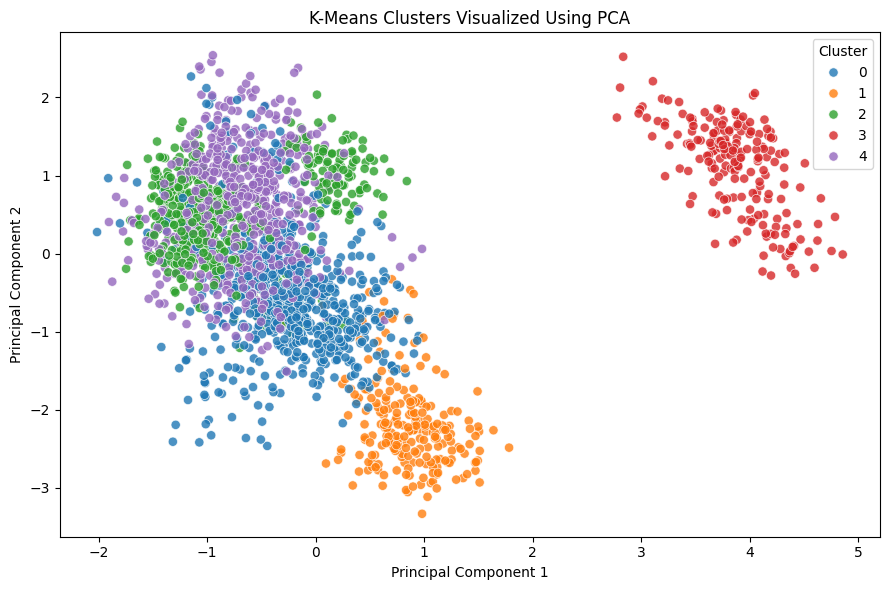

Total variance explained by two PCs: 18.12 %


In [13]:

# Step 4.5: Reduce features to two principal components
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_df)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": kmeans_labels
})

# Plot the clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=45,
    alpha=0.8
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Total variance explained by two PCs:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


### 4.6 Final Interpretation of K-Means Clustering

K-Means clustering was applied to 2,200 observations using 18 standardized agricultural features. The initial model used five clusters, with cluster sizes of 624, 231, 559, 200, and 586 observations.

The Elbow curve showed a continuous decrease in inertia, with the rate of improvement gradually reducing as the number of clusters increased. The Silhouette Score was 0.0873, while the Davies–Bouldin Index was 2.826. These results suggest that the initial five-cluster solution has limited overall separation.

The PCA visualization showed some visibly separated groups and considerable overlap among others. The first two principal components explained 18.12% of the total variance, meaning the two-dimensional visualization represents only a limited portion of the original feature information.

Therefore, five clusters will be treated as an initial baseline rather than the final optimal solution. Further comparison of cluster counts and hierarchical clustering results is needed before selecting the final configuration.

In [14]:

# Step 4.7: Compare different K-Means cluster counts
comparison_results = []

for k in range(2, 16):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled_df)

    comparison_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled_df, labels),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_scaled_df, labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_scaled_df, labels
        )
    })

k_comparison_df = pd.DataFrame(comparison_results)

display(k_comparison_df.round(4))


,k,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,35923.2194,0.2011,1.7088,224.9677
1,3,33653.2367,0.0894,2.9455,194.1127
2,4,32263.2000,0.0803,2.9362,166.4602
3,5,31012.7982,0.0873,2.8260,151.9446
4,6,30195.4583,0.0865,2.8134,136.6667
5,7,29357.4525,0.0908,2.7399,127.5196
6,8,28868.0038,0.0818,2.8298,116.4143
7,9,28480.5644,0.0779,2.8563,106.9268
8,10,28118.6877,0.0762,2.8068,99.3569
9,11,27853.6464,0.0732,2.8163,92.3138


In [15]:

# Step 4.8: Fit the selected K-Means candidate
best_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

best_kmeans_labels = best_kmeans.fit_predict(X_scaled_df)

# Calculate evaluation metrics
best_kmeans_results = pd.DataFrame([{
    "Algorithm": "K-Means",
    "k": 2,
    "Silhouette Score": silhouette_score(
        X_scaled_df, best_kmeans_labels
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_scaled_df, best_kmeans_labels
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_scaled_df, best_kmeans_labels
    ),
    "Inertia": best_kmeans.inertia_
}])

display(best_kmeans_results.round(4))

print("\nCluster sizes:")
print(pd.Series(best_kmeans_labels).value_counts().sort_index())


,Algorithm,k,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Inertia
0,K-Means,2,0.2011,1.7088,224.9677,35923.2194



Cluster sizes:
0     200
1    2000
Name: count, dtype: int64



### K-Means Cluster-Count Selection Using the Elbow Method

The Elbow Method was used to examine the relationship between the number of clusters (k) and the within-cluster sum of squares (inertia). Inertia measures the total squared distance between observations and their assigned cluster centroids. It generally decreases as the number of clusters increases.

The Elbow curve was examined for values of k ranging from 2 to 15. The curve was considered alongside the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index to support the cluster-count decision.

Among the tested values, k = 2 achieved a Silhouette Score of 0.2011, a Davies–Bouldin Index of 1.7088, and a Calinski–Harabasz Index of 224.9677. These results support k = 2 as a candidate among the tested configurations.

However, the Silhouette Score indicates that the separation between clusters is modest. Therefore, k = 2 should not be interpreted as proof that the dataset naturally contains exactly two agricultural groups. The selected configuration is retained for further comparison with Agglomerative Hierarchical Clustering.


## 5. Agglomerative Hierarchical Clustering

### 5.1 Introduction

Agglomerative Hierarchical Clustering is an unsupervised algorithm that begins with individual observations and progressively merges similar groups to build a hierarchy.

Different linkage strategies determine how the distance between clusters is calculated. In this project, we will compare Ward, complete, average, and single linkage strategies using the standardized agricultural features.

In [16]:

# Step 5.2: Compare Agglomerative Clustering linkage strategies
from sklearn.cluster import AgglomerativeClustering

linkage_results = []

for linkage in ["ward", "complete", "average", "single"]:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=linkage
    )

    labels = model.fit_predict(X_scaled_df)

    linkage_results.append({
        "Linkage": linkage,
        "Silhouette Score": silhouette_score(
            X_scaled_df, labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_scaled_df, labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_scaled_df, labels
        )
    })

linkage_comparison = pd.DataFrame(linkage_results)
display(linkage_comparison.round(4))


,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,0.2011,1.7088,224.9677
1,complete,0.1280,2.9745,160.0755
2,average,0.2011,1.7088,224.9677
3,single,0.2011,1.7088,224.9677


### 5.3 Dendrogram Visualization

**Objective:** Visualize the hierarchical merging process using a sample of observations. The dendrogram helps explore possible cluster divisions at different linkage distances.

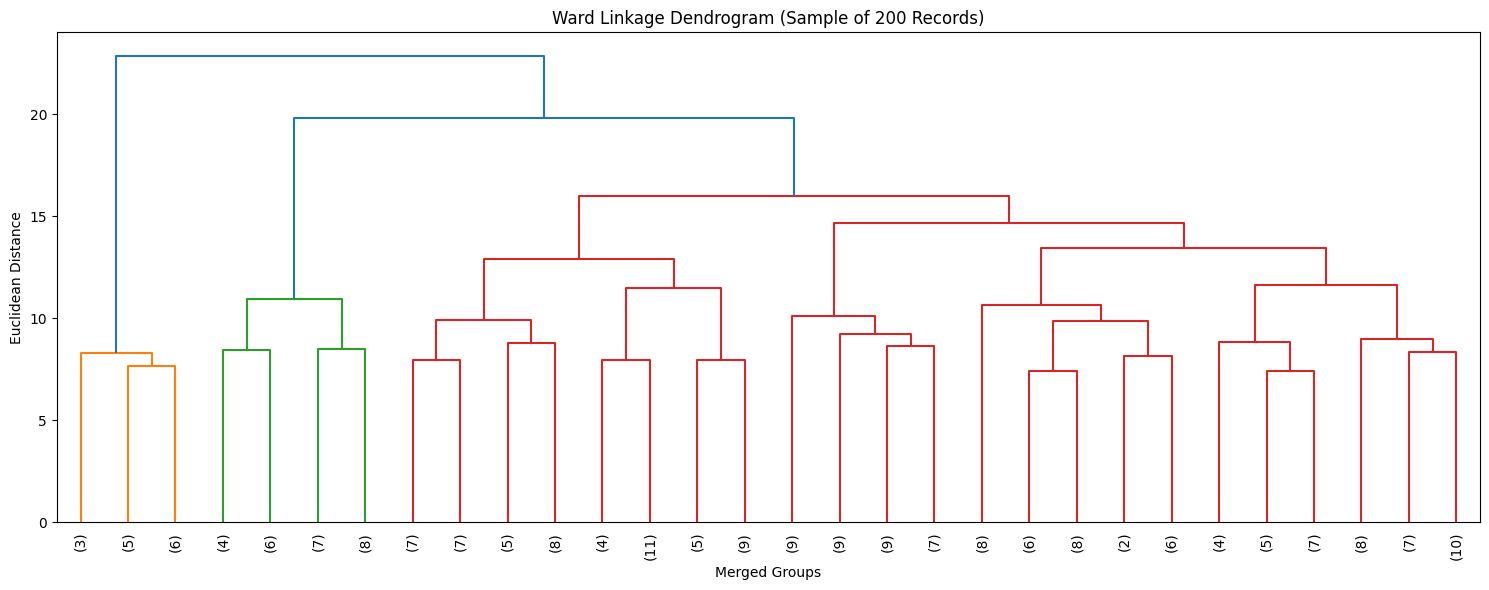

In [17]:

# Step 5.3: Plot a dendrogram using a sample of 200 records
from scipy.cluster.hierarchy import linkage, dendrogram

X_dendrogram = X_scaled_df.sample(
    n=200,
    random_state=42
)

Z = linkage(
    X_dendrogram,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(15, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90
)

plt.title("Ward Linkage Dendrogram (Sample of 200 Records)")
plt.xlabel("Merged Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()


In [18]:

# Step 5.4: Verify cluster assignments for each linkage method
linkage_labels = {}

for method in ["ward", "complete", "average", "single"]:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )
    labels = model.fit_predict(X_scaled_df)
    linkage_labels[method] = labels

    print(f"\n{method.upper()} cluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())

# Compare partitions using Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score

print("\nPartition Similarity:")
for method in ["complete", "average", "single"]:
    score = adjusted_rand_score(
        linkage_labels["ward"],
        linkage_labels[method]
    )
    print(f"Ward vs {method}: {score:.4f}")



WARD cluster sizes:
0    2000
1     200
Name: count, dtype: int64

COMPLETE cluster sizes:
0     415
1    1785
Name: count, dtype: int64

AVERAGE cluster sizes:
0    2000
1     200
Name: count, dtype: int64

SINGLE cluster sizes:
0    2000
1     200
Name: count, dtype: int64

Partition Similarity:
Ward vs complete: 0.5196
Ward vs average: 1.0000
Ward vs single: 1.0000


### 5.4 Final Interpretation of Linkage Comparison and Dendrogram

Agglomerative Hierarchical Clustering was evaluated using Ward, complete, average, and single linkage with two clusters. Ward, average, and single linkage produced identical displayed evaluation metrics, while complete linkage produced a lower Silhouette Score and Calinski–Harabasz Index and a higher Davies–Bouldin Index.

The identical scores require verification by comparing cluster sizes and assignments. The dendrogram illustrated the hierarchical merging of observations at different Euclidean distances. Because it was generated from a sample of 200 records, its structure is exploratory rather than definitive for the complete dataset.

The final hierarchical clustering configuration will be selected after verifying the assignments and comparing the required evaluation metrics.

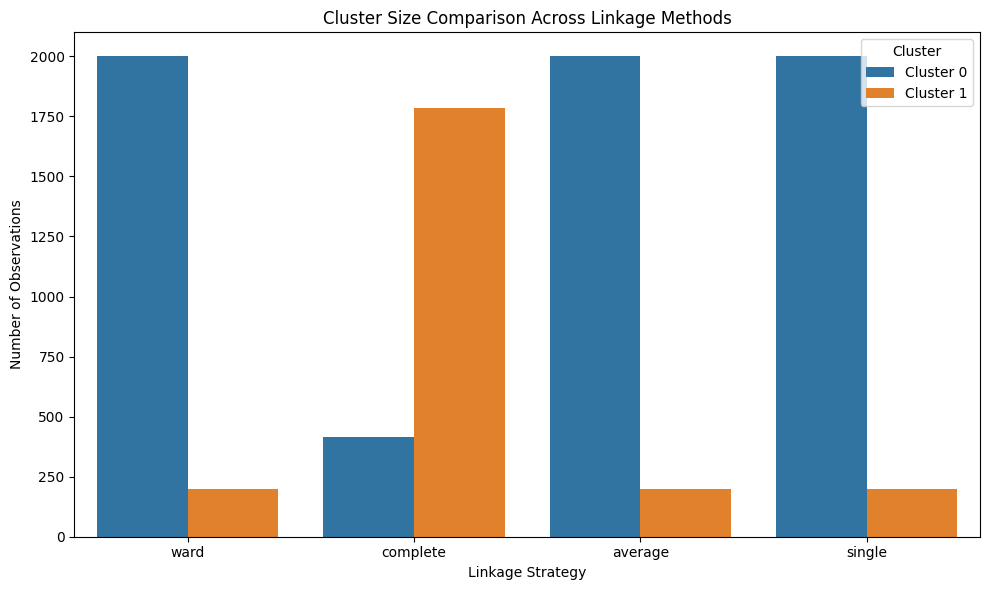

In [19]:

# Step 5.5: Visualize cluster sizes for each linkage method
cluster_size_rows = []

for method, labels in linkage_labels.items():
    counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in counts.items():
        cluster_size_rows.append({
            "Linkage": method,
            "Cluster": f"Cluster {cluster_id}",
            "Size": count
        })

cluster_size_df = pd.DataFrame(cluster_size_rows)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=cluster_size_df,
    x="Linkage",
    y="Size",
    hue="Cluster"
)

plt.title("Cluster Size Comparison Across Linkage Methods")
plt.xlabel("Linkage Strategy")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()



### Agglomerative Hierarchical Clustering Interpretation

Agglomerative Hierarchical Clustering is a bottom-up clustering method. Initially, each observation forms its own cluster. The algorithm repeatedly merges clusters according to a selected linkage criterion until the required number of clusters is obtained.

A dendrogram was generated using a sample of 200 observations to visualize the hierarchical merging process. The vertical axis represents the linkage distance at which clusters are merged. Larger vertical gaps between successive merges can help identify candidate locations for cutting the dendrogram.

The analysis compared four linkage methods:

- **Ward linkage:** Merges clusters to minimize the increase in within-cluster variance.
- **Complete linkage:** Uses the maximum distance between observations in two clusters.
- **Average linkage:** Uses the average pairwise distance between observations in two clusters.
- **Single linkage:** Uses the minimum distance between observations in two clusters.

The clustering evaluation metrics were used to compare the resulting partitions. The Silhouette Score measures how well observations fit within their assigned clusters compared with neighboring clusters. Higher values are generally preferred. The Davies–Bouldin Index measures within-cluster dispersion relative to separation between clusters, with lower values generally preferred. The Calinski–Harabasz Index compares between-cluster dispersion with within-cluster dispersion, with higher values generally preferred.

The dendrogram is based on a sample of 200 observations rather than the complete dataset of 2,200 observations. Therefore, its structure should be interpreted as a visualization of the sampled hierarchy, not as a complete representation of every observation.

The linkage method should be selected by considering the evaluation metrics, dendrogram structure, cluster sizes, and interpretability of the resulting groups.


## 6. Cluster Visualization and Model Comparison

### 6.1 PCA Visualization

Principal Component Analysis (PCA) reduces the number of dimensions while retaining as much variance as possible. In this project, PCA is used to visualize the cluster assignments generated by K-Means and Agglomerative Clustering in two dimensions.

PCA is used for visualization; the clustering models are fitted using the standardized feature matrix.

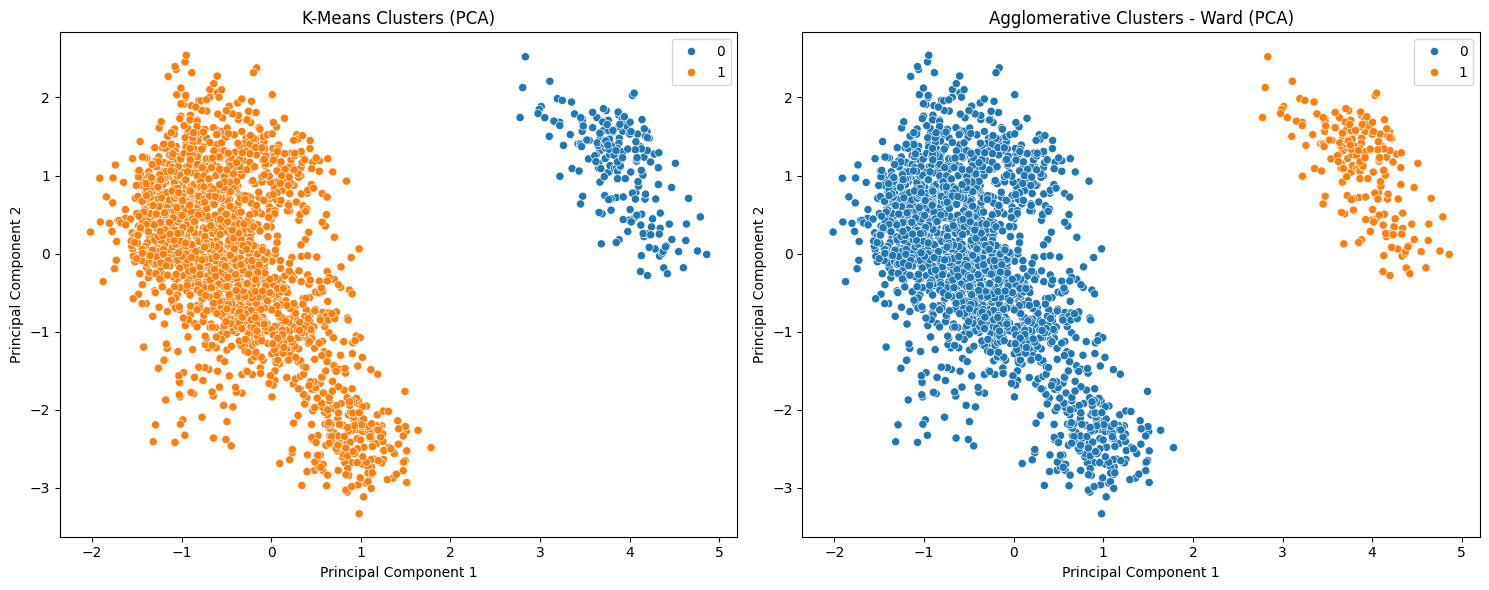

Variance explained by two principal components: 18.12 %


In [20]:

# Step 6.1: Prepare PCA visualization for both algorithms
from sklearn.decomposition import PCA

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# K-Means visualization
sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=best_kmeans_labels,
    palette="tab10",
    s=35,
    ax=axes[0],
    legend="full"
)
axes[0].set_title("K-Means Clusters (PCA)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# Agglomerative visualization using Ward linkage
ward_labels = linkage_labels["ward"]

sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=ward_labels,
    palette="tab10",
    s=35,
    ax=axes[1],
    legend="full"
)
axes[1].set_title("Agglomerative Clusters - Ward (PCA)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

print(
    "Variance explained by two principal components:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


### 6.2 t-SNE Visualization

t-SNE is a nonlinear dimensionality-reduction technique that attempts to preserve local similarities between observations. It is used here to visualize the clustering assignments in two dimensions.

The t-SNE plot is exploratory and should not be treated as proof of cluster quality or as a replacement for the required evaluation metrics.

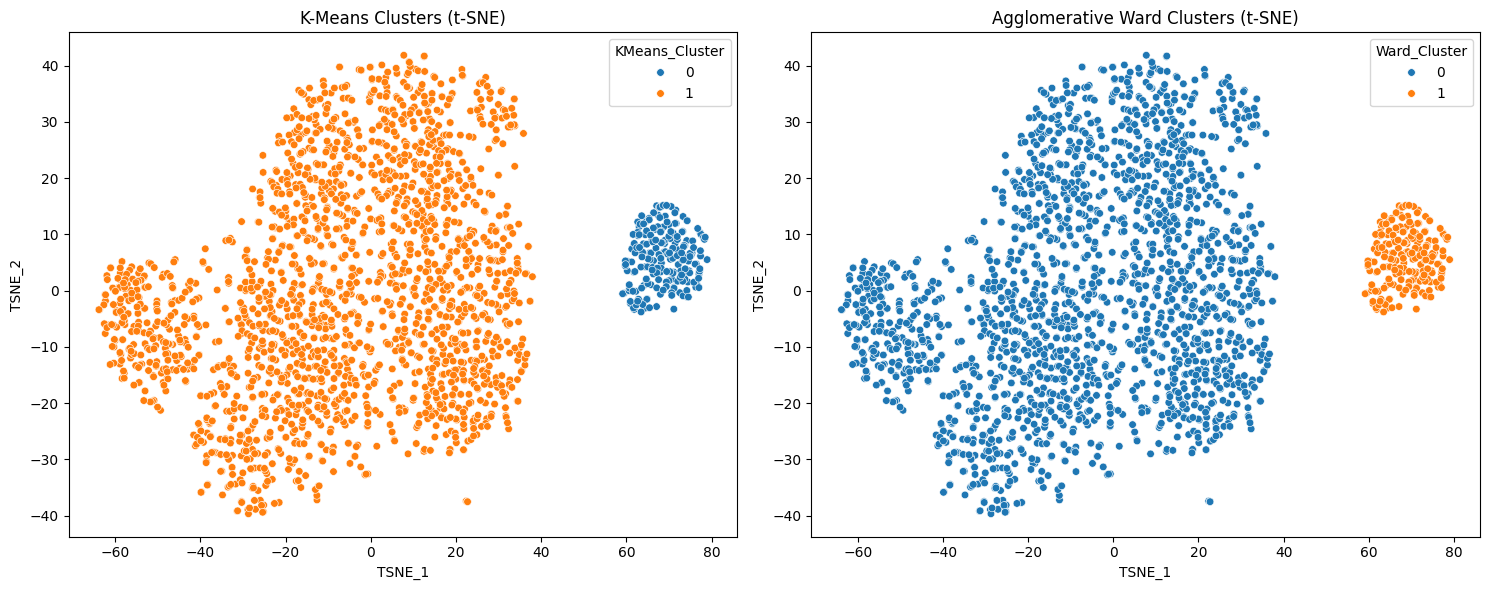

In [21]:

# Step 6.2: Create a t-SNE visualization
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled_df)

tsne_df = pd.DataFrame({
    "TSNE_1": X_tsne[:, 0],
    "TSNE_2": X_tsne[:, 1],
    "KMeans_Cluster": best_kmeans_labels,
    "Ward_Cluster": ward_labels
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=tsne_df,
    x="TSNE_1",
    y="TSNE_2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=30,
    ax=axes[0]
)
axes[0].set_title("K-Means Clusters (t-SNE)")

sns.scatterplot(
    data=tsne_df,
    x="TSNE_1",
    y="TSNE_2",
    hue="Ward_Cluster",
    palette="tab10",
    s=30,
    ax=axes[1]
)
axes[1].set_title("Agglomerative Ward Clusters (t-SNE)")

plt.tight_layout()
plt.show()


In [22]:

# Step 7.1: Compare the final clustering candidates
final_results = []

# K-Means
final_results.append({
    "Algorithm": "K-Means",
    "Configuration": "k=2",
    "Silhouette Score": silhouette_score(
        X_scaled_df, best_kmeans_labels
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_scaled_df, best_kmeans_labels
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_scaled_df, best_kmeans_labels
    )
})

# Agglomerative clustering with each linkage
for method, labels in linkage_labels.items():
    final_results.append({
        "Algorithm": "Agglomerative",
        "Configuration": f"linkage={method}, k=2",
        "Silhouette Score": silhouette_score(
            X_scaled_df, labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_scaled_df, labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_scaled_df, labels
        )
    })

final_comparison = pd.DataFrame(final_results)
display(final_comparison.round(4))


,Algorithm,Configuration,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,k=2,0.2011,1.7088,224.9677
1,Agglomerative,"linkage=ward, k=2",0.2011,1.7088,224.9677
2,Agglomerative,"linkage=complete, k=2",0.1280,2.9745,160.0755
3,Agglomerative,"linkage=average, k=2",0.2011,1.7088,224.9677
4,Agglomerative,"linkage=single, k=2",0.2011,1.7088,224.9677



### Clustering Evaluation and Model Comparison

K-Means and Agglomerative Hierarchical Clustering were evaluated using three internal clustering metrics: Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index.

The Silhouette Score evaluates how closely observations fit within their assigned clusters compared with neighboring clusters. Higher values generally indicate better-defined clusters.

The Davies–Bouldin Index measures the relationship between within-cluster dispersion and separation between clusters. Lower values generally indicate better separation.

The Calinski–Harabasz Index compares between-cluster dispersion with within-cluster dispersion. Higher values generally indicate more distinct clusters.

These metrics measure different aspects of cluster quality, so they should be interpreted together rather than relying on a single score. The final comparison should also consider cluster sizes, PCA visualizations, and the interpretability of the resulting groups.

The selected K-Means configuration with two clusters achieved a Silhouette Score of 0.2011, a Davies–Bouldin Index of 1.7088, and a Calinski–Harabasz Index of 224.9677. These results provide a baseline for comparison with the hierarchical clustering configurations.

A relatively low Silhouette Score indicates that the clusters have limited separation. Therefore, the selected solution should be treated as a useful candidate for exploratory analysis rather than proof of naturally distinct agricultural groups.

The external comparison with the known crop labels is a separate evaluation step. The Adjusted Rand Index and Normalized Mutual Information measure agreement between the discovered clusters and the known labels; they were not used to form the clusters.


 ## 8. Cluster Interpretation Using Known Crop Labels

### Objective

Examine the distribution of known crop categories within the clusters after model fitting. This analysis helps assess whether the discovered groups have interpretable relationships with the known crop categories.

The crop labels are used only for post-clustering interpretation and are not used as input features during model training.

In [24]:

# Step 8.1: Create a separate analysis DataFrame
cluster_analysis = pd.DataFrame({
    "Crop_Label": y_true.reset_index(drop=True),
    "KMeans_Cluster": best_kmeans_labels,
    "Ward_Cluster": ward_labels
})

# Step 8.2: Examine crop categories in K-Means clusters
kmeans_crop_table = pd.crosstab(
    cluster_analysis["KMeans_Cluster"],
    cluster_analysis["Crop_Label"]
)

print("Crop Category Counts Within K-Means Clusters:")
display(kmeans_crop_table)

# Step 8.3: Examine crop categories in Ward clusters
ward_crop_table = pd.crosstab(
    cluster_analysis["Ward_Cluster"],
    cluster_analysis["Crop_Label"]
)

print("Crop Category Counts Within Ward Clusters:")
display(ward_crop_table)


Crop Category Counts Within K-Means Clusters:


Crop_Label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,
0,100,0,0,0,0,0,0,100,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,100,100,100,100,100,100,0,100,100,...,100,100,100,100,100,100,100,100,100,100


Crop Category Counts Within Ward Clusters:


Crop_Label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
Ward_Cluster,,,,,,,,,,,,,,,,,,,,,
0,0,100,100,100,100,100,100,0,100,100,...,100,100,100,100,100,100,100,100,100,100
1,100,0,0,0,0,0,0,100,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:

# Step 8.4: Show the percentage distribution of crop labels
print("K-Means Crop Distribution Within Each Cluster (%)")
display(
    pd.crosstab(
        cluster_analysis["KMeans_Cluster"],
        cluster_analysis["Crop_Label"],
        normalize="index"
    ).mul(100).round(2)
)

print("Ward Crop Distribution Within Each Cluster (%)")
display(
    pd.crosstab(
        cluster_analysis["Ward_Cluster"],
        cluster_analysis["Crop_Label"],
        normalize="index"
    ).mul(100).round(2)
)


K-Means Crop Distribution Within Each Cluster (%)


Crop_Label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,
0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,5.0,5.0,5.0,5.0,5.0,5.0,0.0,5.0,5.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0


Ward Crop Distribution Within Each Cluster (%)


Crop_Label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
Ward_Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0,5.0,5.0,5.0,5.0,5.0,5.0,0.0,5.0,5.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
1,50.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 8.5 Final Interpretation of Cluster Composition

The cluster composition analysis revealed that K-Means with two clusters separated the 200 Apple and Grapes observations from the remaining 2,000 observations. Each of these two crop categories contributed 100 observations to the smaller cluster. The larger cluster contained the remaining 20 crop categories, each contributing 100 observations.

Agglomerative Clustering with Ward linkage produced the same grouping, although the cluster IDs were reversed. This agrees with the identical internal evaluation scores obtained for the two models.

The result suggests that Apple and Grapes have sufficiently distinct patterns in the selected feature space to be separated from the other crop categories under this two-cluster configuration. However, the remaining 20 crop categories were grouped together, so the solution does not distinguish all crop types individually. The result should therefore be interpreted as a broad grouping of agricultural observations rather than a complete crop classification system.

### 8.6 Post-Clustering Validation

The known crop labels are compared with the generated cluster assignments using external validation metrics. These metrics help evaluate agreement between the unsupervised clusters and the known crop categories without using those categories during model fitting.

In [26]:

# Step 8.6: Compare clusters with known labels after fitting
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

external_results = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Adjusted Rand Index": adjusted_rand_score(
            y_true, best_kmeans_labels
        ),
        "Normalized Mutual Information": normalized_mutual_info_score(
            y_true, best_kmeans_labels
        )
    },
    {
        "Algorithm": "Agglomerative - Ward",
        "Adjusted Rand Index": adjusted_rand_score(
            y_true, ward_labels
        ),
        "Normalized Mutual Information": normalized_mutual_info_score(
            y_true, ward_labels
        )
    }
])

display(external_results.round(4))


,Algorithm,Adjusted Rand Index,Normalized Mutual Information
0,K-Means,0.0185,0.1794
1,Agglomerative - Ward,0.0185,0.1794


### 8.7 Final Interpretation of External Validation

The external validation results produced an Adjusted Rand Index of 0.0185 and a Normalized Mutual Information score of 0.1794 for both K-Means and Agglomerative Clustering using Ward linkage.

The low ARI indicates limited agreement between the generated clusters and the known crop categories after adjusting for chance. The NMI score indicates some shared information, but the two-cluster solution does not represent all 22 crop categories individually.

These results highlight an important limitation of the selected configuration. Although the internal metrics favored two clusters among the tested K-Means configurations, the external validation scores show that this solution has limited alignment with the known crop categories. The cluster count should therefore be selected according to the project's objective, rather than assuming that the best internal metrics guarantee meaningful crop-level grouping.

## 9. Overall Conclusion

This project investigated patterns in the Crop Recommendation dataset using K-Means and Agglomerative Hierarchical Clustering. The workflow included exploratory data analysis, feature selection, standardization, cluster-count comparison, linkage evaluation, internal clustering metrics, PCA and t-SNE visualizations, and post-clustering interpretation using known crop labels.

Among the tested K-Means configurations, two clusters achieved the highest Silhouette Score and Calinski–Harabasz Index and the lowest Davies–Bouldin Index. The two-cluster Ward solution produced identical internal metrics and the same grouping as K-Means. Both methods separated the Apple and Grapes observations from the other 20 crop categories.

However, the Silhouette Score of 0.2011 indicates limited overall separation, and the two-cluster solution does not distinguish every crop category individually. The findings therefore demonstrate a broad grouping of agricultural observations rather than a complete crop classification system.

Overall, the project demonstrates how unsupervised learning can explore similarities in agricultural data and how internal metrics, visualization, and post-clustering validation can be combined to interpret the results critically.